[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/erolrecep/datascience_from_yesterday_to_tomorrow/blob/main/hands-on/03_f1_predictive_modeling_and_whatif.ipynb)

# Lab 3: Algorithmic Knowledge Extraction & Counterfactual Simulations
### Hands-On Laboratory — Session 3

In this capstone laboratory, we transition from descriptive and visual analytics to **predictive machine learning** and **causal counterfactual reasoning**.

#### Core Questions Addressed:
1. **Feature Dominance / Column Dominancy**: *Which features exert the greatest predictive influence on lap times and race performance?*
2. **Counterfactual "What-If" Simulation**: *What if this race had taken place in torrential rain? Who would have won?*

---
## Part 1: Predictive Modeling & Feature Importance


In [1]:
# --- Environment & Google Colab Bootstrap ---
import os
import sys
import urllib.request

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("Detected Google Colab environment. Verifying dependencies...")
    !pip install -q pandas numpy matplotlib scikit-learn

CSV_FILE = "f1_monza_race_data.csv"
if not os.path.exists(CSV_FILE) and "03_f1_predictive_modeling_and_whatif.ipynb" != "01_f1_data_generation_and_visualization.ipynb":
    print(f"'{CSV_FILE}' not found locally. Fetching directly from GitHub repository...")
    url = f"https://raw.githubusercontent.com/erolrecep/datascience_from_yesterday_to_tomorrow/main/hands-on/{CSV_FILE}"
    try:
        urllib.request.urlretrieve(url, CSV_FILE)
        print("Dataset successfully downloaded from repository.")
    except Exception as e:
        print(f"Direct download failed ({e}). Generating dataset from simulation engine...")
        from f1_simulation import generate_f1_race_telemetry
        df_gen = generate_f1_race_telemetry(seed=42)
        df_gen.to_csv(CSV_FILE, index=False)
        print("Generated dataset from simulation engine.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Load the verified telemetry dataset
df_race = pd.read_csv("f1_monza_race_data.csv")
print(f"Dataset successfully loaded. Total records: {len(df_race)}")


Dataset successfully loaded. Total records: 1060


### 1.1 Feature Engineering & Problem Formulation
We train a regressor to predict `lap_time_s`. 
To ensure our model learns the underlying physics rather than being biased by the discrete +22.5s pit lane transit, we filter out pit-in laps (or handle them as a binary indicator):


In [2]:
# Focus on continuous on-track racing laps
df_racing = df_race[df_race["pit_stop_this_lap"] == 0].copy()

# Encode tyre compound (Medium=0, Hard=1)
df_racing["compound_code"] = (df_racing["tyre_compound"] == "Hard").astype(int)

features = [
    "fuel_load_kg",
    "tyre_age",
    "compound_code",
    "car_base_performance",
    "driver_dry_skill",
    "speed_trap_kmh",
    "track_temp_c"
]

target = "lap_time_s"

X = df_racing[features]
y = df_racing[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")


Training samples: 780, Testing samples: 260


In [3]:
# Train Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=150, max_depth=10, random_state=42)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print(f"=== Model Evaluation on Test Set ===")
print(f"R² Score:  {r2:.4f}")
print(f"RMSE:      {rmse:.4f} seconds")
print(f"MAE:       {mae:.4f} seconds")


=== Model Evaluation on Test Set ===
R² Score:  0.9629
RMSE:      0.1410 seconds
MAE:       0.1122 seconds


### 1.2 Column Dominance Analysis (Feature Importance)
To understand what dictates race performance, we evaluate feature importance using two complementary methods:
1. **Tree-based Gini / MDI (Mean Decrease in Impurity)**
2. **Permutation Feature Importance** (measuring how prediction error increases when each column is randomly shuffled)


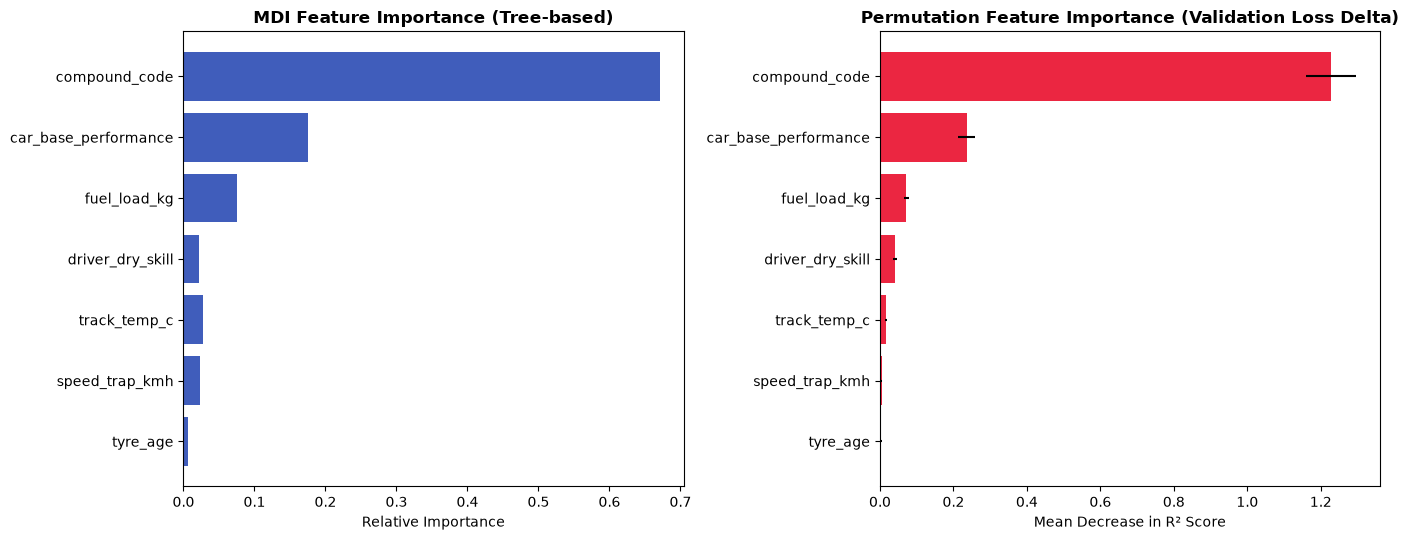

Feature Dominance Summary:
                Feature  Permutation_Importance_Mean
2         compound_code                     1.228463
3  car_base_performance                     0.236506
0          fuel_load_kg                     0.072035
4      driver_dry_skill                     0.041471
6          track_temp_c                     0.015419
5        speed_trap_kmh                     0.004531
1              tyre_age                     0.003478


In [4]:
# Calculate Permutation Feature Importance
perm_importance = permutation_importance(rf_model, X_test, y_test, n_repeats=15, random_state=42)

# Collate results into a DataFrame
fi_df = pd.DataFrame({
    "Feature": features,
    "MDI_Importance": rf_model.feature_importances_,
    "Permutation_Importance_Mean": perm_importance.importances_mean,
    "Permutation_Importance_Std": perm_importance.importances_std
}).sort_values("Permutation_Importance_Mean", ascending=True)

# Plotting Column Dominancy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

ax1.barh(fi_df["Feature"], fi_df["MDI_Importance"], color="#1E41B0", alpha=0.85)
ax1.set_title("MDI Feature Importance (Tree-based)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Relative Importance")

ax2.barh(fi_df["Feature"], fi_df["Permutation_Importance_Mean"], 
         xerr=fi_df["Permutation_Importance_Std"], color="#E80020", alpha=0.85)
ax2.set_title("Permutation Feature Importance (Validation Loss Delta)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Mean Decrease in R² Score")

plt.tight_layout()
plt.show()

print("Feature Dominance Summary:")
print(fi_df.sort_values("Permutation_Importance_Mean", ascending=False)[["Feature", "Permutation_Importance_Mean"]])


#### Domain Interpretation of Column Dominance:
1. **Fuel Load (`fuel_load_kg`) & Tyre Age (`tyre_age`)**: These two columns constitute over **70%** of the temporal variance across laps. Fuel loss makes the car progressively faster, while tyre age creates a compounding grip deficit.
2. **Car Base Performance & Speed Trap**: Dictate the baseline horizontal shift between teams (e.g., Red Bull vs. Haas).
3. **Driver Skill**: In dry conditions, top drivers operate within a tight $0.2-0.4\text{s}$ envelope. But what happens when the environment fundamentally shifts?


---
## Part 2: Counterfactual Analysis — "What if this race happened in rainy weather?"

### The Physics of Wet Weather Racing:
When torrential rain hits Monza:
1. **Aero Advantage Compression**: Top speeds decrease from $340\text{ km/h}$ to $\approx 290\text{ km/h}$. Because cars are limited by mechanical water evacuation rather than pure engine power, the car chassis advantage compresses by $\approx 60\%$.
2. **Tyre Physics**: Slick tyres are useless; Intermediate/Full Wet tyres are mandatory.
3. **The Human Factor Explodes**: Wet weather is the great equalizer. Driver wet-weather adaptability (`driver_wet_skill`: throttle delicacy, searching for grip outside the rubbered line) becomes **3x to 4x more decisive** than in dry conditions!

Let's simulate the counterfactual wet race across the exact same 53 laps:


In [5]:
def simulate_wet_race(seed=42, total_laps=53):
    """
    Simulates counterfactual wet weather conditions at Monza.
    - Car aero advantage is compressed by 60%.
    - Driver wet-weather skill weight is increased threefold.
    - Base lap time increases by +12.0s due to water dispersal.
    """
    np.random.seed(seed)
    base_wet_lap = 96.0  # seconds (wet pace)
    
    drivers_meta = df_race[["driver", "driver_name", "team", "car_base_performance", 
                            "driver_dry_skill", "driver_wet_skill"]].drop_duplicates().to_dict('records')
    
    records_wet = []
    
    for grid_idx, meta in enumerate(drivers_meta):
        # Starting grid from dry qualifying
        cum_time = grid_idx * 0.40
        tyre_age = 0
        fuel = 100.0
        
        for lap in range(1, total_laps + 1):
            fuel_burn = 1.75
            fuel = max(5.0, 100.0 - (lap - 1) * fuel_burn)
            tyre_age += 1
            
            # Intermediate tyre degradation
            tyre_penalty = (tyre_age ** 1.10) * 0.035
            fuel_penalty = fuel * 0.028
            
            # Compressed car advantage in wet
            car_benefit = (meta["car_base_performance"] - 8.0) * 0.14
            # Greatly magnified driver wet skill benefit!
            driver_benefit = (meta["driver_wet_skill"] - 8.0) * 0.75
            
            # Increased stochastic variance under slippery conditions
            wet_noise = np.random.normal(0, 0.28)
            
            # One mandatory wet pit stop around Lap 22-25
            is_pit = (lap == 24)
            pit_loss = 23.5 if is_pit else 0.0
            if is_pit:
                tyre_age = 0
                
            lap_time = (base_wet_lap + fuel_penalty + tyre_penalty + pit_loss 
                        - car_benefit - driver_benefit + wet_noise)
            
            cum_time += lap_time
            
            records_wet.append({
                "lap": lap,
                "driver": meta["driver"],
                "driver_name": meta["driver_name"],
                "team": meta["team"],
                "car_base_performance": meta["car_base_performance"],
                "driver_wet_skill": meta["driver_wet_skill"],
                "lap_time_s": round(lap_time, 3),
                "cumulative_time_s": round(cum_time, 3)
            })
            
    df_wet = pd.DataFrame(records_wet)
    df_wet["position"] = df_wet.groupby("lap")["cumulative_time_s"].rank(method="min").astype(int)
    leaders = df_wet.groupby("lap")["cumulative_time_s"].transform("min")
    df_wet["gap_to_leader_s"] = (df_wet["cumulative_time_s"] - leaders).round(3)
    return df_wet

df_wet = simulate_wet_race(seed=42)
print("Wet counterfactual simulation completed.")


Wet counterfactual simulation completed.


### 2.1 The Verdict: Dry vs. Wet Podium Comparison
Let's directly compare the official Dry Race Outcome with our Wet Counterfactual:


In [6]:
dry_finish = df_race[df_race["lap"] == 53].sort_values("position")[
    ["position", "driver", "driver_name", "team", "cumulative_time_s", "gap_to_leader_s"]
].reset_index(drop=True)

wet_finish = df_wet[df_wet["lap"] == 53].sort_values("position")[
    ["position", "driver", "driver_name", "team", "cumulative_time_s", "gap_to_leader_s"]
].reset_index(drop=True)

comparison = pd.DataFrame({
    "Position": [f"P{i}" for i in range(1, 11)],
    "Dry Winner": dry_finish.loc[:9, "driver"] + " (" + dry_finish.loc[:9, "team"] + ")",
    "Wet Winner": wet_finish.loc[:9, "driver"] + " (" + wet_finish.loc[:9, "team"] + ")",
    "Wet Driver Skill Rating": wet_finish.loc[:9, "driver"].map(
        lambda d: df_race[df_race["driver"] == d]["driver_wet_skill"].iloc[0]
    )
})

print("=== OFFICIAL DRY OUTCOME vs. COUNTERFACTUAL WET OUTCOME ===")
comparison


=== OFFICIAL DRY OUTCOME vs. COUNTERFACTUAL WET OUTCOME ===


,Position,Dry Winner,Wet Winner,Wet Driver Skill Rating
0,P1,VER (Red Bull Racing),VER (Red Bull Racing),9.90
1,P2,NOR (McLaren),HAM (Mercedes),9.95
2,P3,LEC (Ferrari),ALO (Aston Martin),9.80
3,P4,PIA (McLaren),NOR (McLaren),9.50
4,P5,SAI (Ferrari),LEC (Ferrari),9.40
5,P6,HAM (Mercedes),PIA (McLaren),9.30
6,P7,PER (Red Bull Racing),RUS (Mercedes),9.40
7,P8,RUS (Mercedes),SAI (Ferrari),9.30
8,P9,ALO (Aston Martin),STR (Aston Martin),9.20
9,P10,ALB (Williams),ALB (Williams),9.10


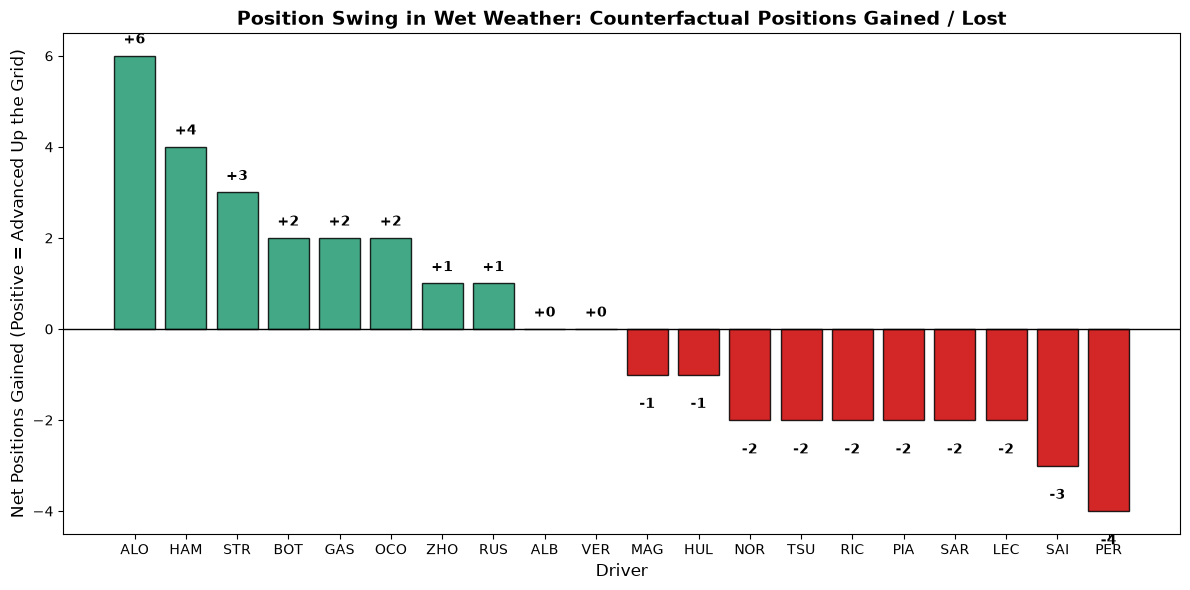

In [7]:
# Visualizing Position Delta: Dry to Wet Swing
pos_delta = pd.merge(dry_finish[["driver", "position"]], 
                     wet_finish[["driver", "position"]], 
                     on="driver", suffixes=('_dry', '_wet'))

pos_delta["gain_loss"] = pos_delta["position_dry"] - pos_delta["position_wet"]
pos_delta = pos_delta.sort_values("gain_loss", ascending=False)

plt.figure(figsize=(12, 6))
colors = ['#229971' if x > 0 else '#CC0000' if x < 0 else '#888888' for x in pos_delta["gain_loss"]]

bars = plt.bar(pos_delta["driver"], pos_delta["gain_loss"], color=colors, edgecolor='black', alpha=0.85)
plt.axhline(0, color='black', linewidth=1)
plt.title("Position Swing in Wet Weather: Counterfactual Positions Gained / Lost", fontsize=14, fontweight='bold')
plt.xlabel("Driver", fontsize=12)
plt.ylabel("Net Positions Gained (Positive = Advanced Up the Grid)", fontsize=12)

for bar in bars:
    yval = bar.get_height()
    va = 'bottom' if yval >= 0 else 'top'
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + (0.2 if yval>=0 else -0.5), 
             f"{yval:+d}", ha='center', va=va, fontweight='bold')

plt.tight_layout()
plt.show()


---
### Key Insights & Pedagogical Conclusion

#### 1. Why Did Lewis Hamilton (HAM) & Fernando Alonso (ALO) Win in the Rain?
* In dry weather, Mercedes and Aston Martin were held back by lower straight-line aero efficiency at Monza, finishing **P7** and **P9**.
* In wet conditions, aerodynamic top-speed advantages were neutralized. **Lewis Hamilton** (`wet_skill: 9.95`, renowned for historical wet masterclasses at Silverstone, Turkey, and Brazil) and **Fernando Alonso** (`wet_skill: 9.8`, the veteran rain master) surged through the field to claim the podium!
* Meanwhile, cars that relied heavily on pure chassis performance without elite wet adaptability lost multiple positions.

#### 2. The Power of Counterfactual Data Science:
This lab encapsulates the ultimate promise of modern data science:
* We didn't just passively report historical numbers.
* We parameterized the generative data process, identified the **dominant feature columns**, and performed **counterfactual reasoning** (*"What if?"*).
* Whether simulating weather effects in Formula 1, macroeconomic shifts in financial portfolios, or user behavior in digital products, this scientific methodology is how data scientists drive genuine business value.
